In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import datetime
import pytz
import seaborn as sns
sns.set_theme(style="whitegrid")

In [29]:
results_dir = '/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/final'
res_dirs = [d for d in os.listdir(results_dir) if os.path.isdir(os.path.join(results_dir, d))]
res_dirs = [d for d in res_dirs if '5Feb' not in d]
res_dict = {}
for dir in res_dirs:
    loc_file = os.path.join(results_dir, dir, 'loc.txt')
    baseline_file = os.path.join(results_dir, dir, 'baseline.txt')
    with open(loc_file, 'r') as f:
        loc_data = f.read().splitlines()
    with open(baseline_file, 'r') as f:
        baseline_data = f.read().splitlines()
    # for line in loc_data:
    #     print(line)
    gt = np.array(loc_data[2].split(' '), dtype=np.float64)
    coarse_loc = np.array(loc_data[4].split(' '), dtype=np.float64)
    coarse_loc_err = np.array(loc_data[6].split(' '), dtype=np.float64)
    total_sats, train_sats = np.array(loc_data[8].split(' '), dtype=np.int32)
    test_sats = total_sats - train_sats
    phase_err_overall = np.array(loc_data[10].split(' ')[-1], dtype=np.float64)
    x_err = np.array(loc_data[10].split(' ')[0], dtype=np.float64)
    y_err = np.array(loc_data[10].split(' ')[1], dtype=np.float64)
    # calculate coordinate from error with respect to gt
    latitude, longitude = gt
    r_earth = 6378.1 #km
    dx = x_err/1000
    dy = y_err/1000
    new_latitude  = latitude  + (dy / r_earth) * (180 / np.pi)
    new_longitude = longitude + (dx / r_earth) * (180 / np.pi) / np.cos(latitude * np.pi/180)
    
    dopp_err_overall = np.array(loc_data[12].split(' ')[-1], dtype=np.float64)
    avg_err_overall = np.array(loc_data[14].split(' ')[-1], dtype=np.float64)
    phase_err_persat_lines, dopp_err_persat_lines, avg_err_persat_lines = loc_data[16:16+test_sats], loc_data[16+test_sats+1:16+2*test_sats+1], loc_data[16+2*test_sats+2:16+3*test_sats+2]
    phase_err_persat = np.array([float(err.split(' ')[-1]) for err in phase_err_persat_lines])
    dopp_err_persat = np.array([float(err.split(' ')[-1]) for err in dopp_err_persat_lines])
    avg_err_persat = np.array([float(err.split(' ')[-1]) for err in avg_err_persat_lines])
    #append to dictionary
    res_dict[dir] = {}
    res_dict[dir]['gt'] = gt
    res_dict[dir]['loc_coords'] = [new_latitude, new_longitude]
    res_dict[dir]['coarse_loc'] = coarse_loc
    res_dict[dir]['coarse_loc_err'] = coarse_loc_err
    res_dict[dir]['total_sats'] = total_sats
    res_dict[dir]['train_sats'] = train_sats
    res_dict[dir]['test_sats'] = test_sats
    res_dict[dir]['phase_err_overall'] = phase_err_overall
    res_dict[dir]['dopp_err_overall'] = dopp_err_overall
    res_dict[dir]['avg_err_overall'] = avg_err_overall
    res_dict[dir]['phase_err_persat'] = phase_err_persat
    res_dict[dir]['dopp_err_persat'] = dopp_err_persat
    res_dict[dir]['avg_err_persat'] = avg_err_persat

    sat_ids = sio.loadmat(os.path.join(results_dir, dir, 'phase_comp.mat'))['id_dict']
    sat_ids = [id[0] for id in sat_ids[0]]
    
    tle_path = os.path.join(results_dir, dir, 'Starlink.tle')
    tle_dict = {}
    with open(tle_path, 'r') as f:
        tle_data = f.read().splitlines()
        for idx,line in enumerate(tle_data):
            if 'STARLINK' in line:
                sat_id = line.strip()
                l = tle_data[idx+1].split(' ')
                l = [x for x in l if x]
                tle_dict[sat_id] = l[3]
    res_dict[dir]['sat_id_epoch'] = []
    cap_time = sio.loadmat(os.path.join(results_dir, dir, 'info.mat'))['start_time'][0][0]
    for id in sat_ids[train_sats:]:
        epoch = tle_dict[id]
        year = int('20' + epoch[:2])
        day = int(epoch[2:5])
        # print(day)
        time = float(epoch[5:])
        hour = int(time*24)
        min = int((time*24 - hour)*60)
        sec = int(((time*24 - hour)*60 - min)*60)
        # print(id, f'{year} {day} {hour} {min} {sec}', dir)
        # convert to UTC timestamp
        ts = datetime.datetime(year, 1, 1, 0, 0, 0, 0, pytz.UTC) + datetime.timedelta(day - 1, hours=hour, minutes=min, seconds=sec)
        ts = ts.timestamp()
        # print(ts, cap_time, ((cap_time-ts)/60)/60)
        res_dict[dir]['sat_id_epoch'].append([id, ts, cap_time, ((cap_time-ts)/60)/60])

    dopp_baseline_overall = baseline_data[3].split(' ')[-1]
    # persat baseline
    dopp_baseline_persat_lines = baseline_data[7::2]
    dopp_baseline_persat = np.array([err.split(' ')[-1] for err in dopp_baseline_persat_lines], dtype=np.float64)
    res_dict[dir]['dopp_baseline_overall'] = dopp_baseline_overall
    res_dict[dir]['dopp_baseline_persat'] = dopp_baseline_persat[train_sats:]
    print(dopp_baseline_overall, phase_err_overall)


2800.1202664062807 1965.5886648852197
2576.484019266021 1782.3264171827332
2529.385138837492 2036.2612652617888
5086.917296204977 2189.2483327429113
2549.115431080448 2663.790609185643
4576.775371232964 714.2045428920565
2653.12478092064 607.1882398791253
3459.6135453023962 2839.9741006924196
2185.073068362668 1423.0957043724923
5661.1894583294215 2243.9310112327744
3926.298029520563 3728.7651174048547


### Plot CDF for overall error

avg_phase_err 2022.87853408468
avg_dopp_err 2931.0243829753354
avg_avg_err 1823.938605191085


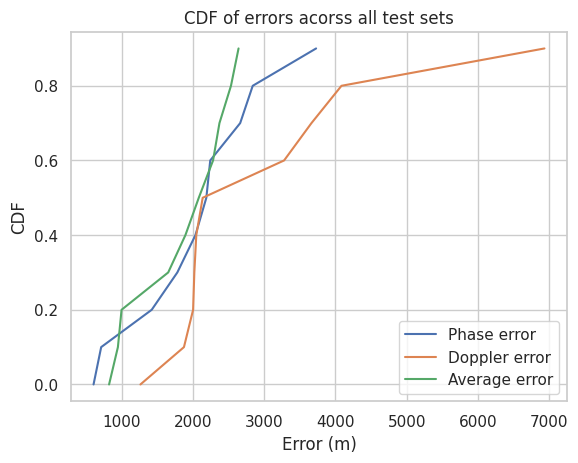

In [22]:
overall_phase_err = [res_dict[dir]['phase_err_overall'] for dir in res_dirs]
overall_dopp_err = [res_dict[dir]['dopp_err_overall'] for dir in res_dirs]
overall_avg_err = [res_dict[dir]['avg_err_overall'] for dir in res_dirs]
avg_phase_err = np.mean(overall_phase_err)
avg_dopp_err = np.mean(overall_dopp_err)
avg_avg_err = np.mean(overall_avg_err)
print('avg_phase_err', avg_phase_err)
print('avg_dopp_err', avg_dopp_err)
print('avg_avg_err', avg_avg_err)

# plot CDF of all errors
overall_phase_err = np.sort(overall_phase_err)
overall_dopp_err = np.sort(overall_dopp_err)
overall_avg_err = np.sort(overall_avg_err)
yvals = np.arange(len(overall_phase_err))/float(len(overall_phase_err))
plt.plot(overall_phase_err, yvals, label='Phase error')
plt.plot(overall_dopp_err, yvals, label='Doppler error')
plt.plot(overall_avg_err, yvals, label='Average error')
plt.legend(loc='lower right')
plt.xlabel('Error (m)')
plt.ylabel('CDF')
plt.title('CDF of errors acorss all test sets')
plt.show()

### Plot CDF with errors from each satellite

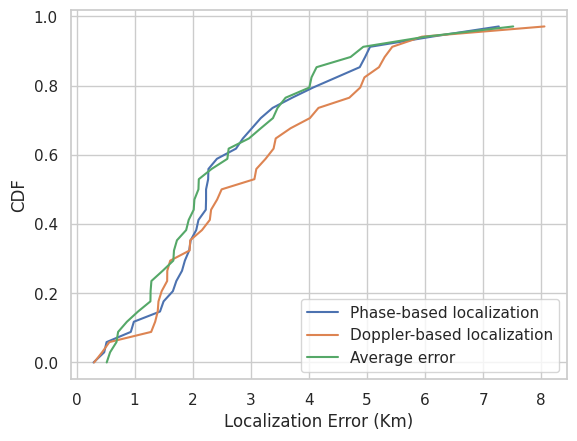

In [23]:
persat_phase_err = [res_dict[dir]['phase_err_persat'] for dir in res_dirs]
persat_dopp_err = [res_dict[dir]['dopp_err_persat'] for dir in res_dirs]
persat_avg_err = [res_dict[dir]['avg_err_persat'] for dir in res_dirs]
# make array flat
persat_phase_err = np.concatenate(persat_phase_err)
persat_dopp_err = np.concatenate(persat_dopp_err)
persat_avg_err = np.concatenate(persat_avg_err)

# plot CDF of errors per satellite
persat_phase_err = np.sort(persat_phase_err)
persat_dopp_err = np.sort(persat_dopp_err)
persat_avg_err = np.sort(persat_avg_err)
yvals = np.arange(len(persat_phase_err))/float(len(persat_phase_err))
plt.plot(persat_phase_err/1000, yvals, label='Phase-based localization')
plt.plot(persat_dopp_err/1000, yvals, label='Doppler-based localization')
plt.plot(persat_avg_err/1000, yvals, label='Average error')
# plt.vlines(avg_phase_err/1000, 0, 0.5, colors='g', linestyles='dashed')
# plt.hlines(0.5, 0, avg_phase_err/1000, colors='g', linestyles='dashed')
plt.legend(loc='lower right')
plt.xlabel('Localization Error (Km)', fontsize=12)
plt.ylabel('CDF', fontsize=12)
# plt.grid()
# plt.title('CDF of errors per satellite')
# plt.show()
#save with high DPI
plt.savefig('persat_cdf.pdf')


Mean: 20267.25688598088 Median: 14648.058371261337 Std: 17450.591759068066
Mean: 2680.66326235508 Median: 2248.3560597352516 Std: 1554.9925541163857


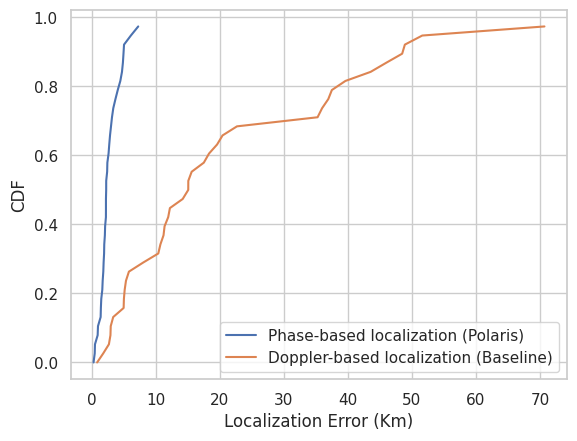

In [32]:
persat_phase_err = [res_dict[dir]['phase_err_persat'] for dir in res_dirs]
persat_dopp_err = [res_dict[dir]['dopp_err_persat'] for dir in res_dirs]
persat_avg_err = [res_dict[dir]['avg_err_persat'] for dir in res_dirs]
persat_dopp_baseline_err = [res_dict[dir]['dopp_baseline_persat'] for dir in res_dirs]
# make array flat
persat_phase_err = np.concatenate(persat_phase_err)
persat_dopp_err = np.concatenate(persat_dopp_err)
persat_avg_err = np.concatenate(persat_avg_err)
persat_dopp_baseline_err = np.concatenate(persat_dopp_baseline_err)
# plot CDF of errors per satellite
persat_phase_err = np.sort(persat_phase_err)
persat_dopp_err = np.sort(persat_dopp_err)
persat_avg_err = np.sort(persat_avg_err)
persat_dopp_baseline_err = np.sort(persat_dopp_baseline_err)
print("Mean:", np.mean(persat_dopp_baseline_err), "Median:", np.median(persat_dopp_baseline_err), "Std:", np.std(persat_dopp_baseline_err))
print("Mean:", np.mean(persat_phase_err), "Median:", np.median(persat_phase_err), "Std:", np.std(persat_phase_err))
yvals = np.arange(len(persat_phase_err))/float(len(persat_phase_err))
plt.plot(persat_phase_err/1000, yvals, label='Phase-based localization (Polaris)')
plt.plot(persat_dopp_baseline_err/1000, yvals, label='Doppler-based localization (Baseline)')
# plt.plot(persat_dopp_err/1000, yvals, label='Doppler-based localization')
# plt.plot(persat_avg_err/1000, yvals, label='Average error')
# plt.vlines(avg_phase_err/1000, 0, 0.5, colors='g', linestyles='dashed')
# plt.hlines(0.5, 0, avg_phase_err/1000, colors='g', linestyles='dashed')
plt.legend(loc='lower right')
plt.xlabel('Localization Error (Km)', fontsize=12)
plt.ylabel('CDF', fontsize=12)
# plt.grid()
# plt.title('CDF of errors per satellite')
# plt.show()
#save with high DPI
plt.savefig('persat_cdf.pdf')


### Correlation between phase and doppler errors

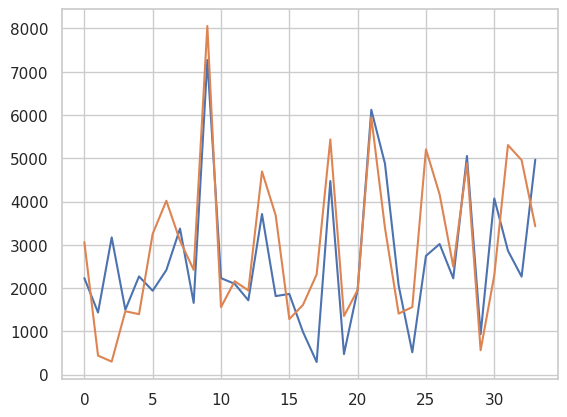

In [24]:
persat_phase_err = [res_dict[dir]['phase_err_persat'] for dir in res_dirs]
persat_dopp_err = [res_dict[dir]['dopp_err_persat'] for dir in res_dirs]
persat_avg_err = [res_dict[dir]['avg_err_persat'] for dir in res_dirs]
# make array flat
persat_phase_err = np.concatenate(persat_phase_err)
persat_dopp_err = np.concatenate(persat_dopp_err)
persat_avg_err = np.concatenate(persat_avg_err)
# get the sat_id_epoch for each satellite
staleness_persat = []
for dir in res_dirs:
    staleness_persat.append([x[3] for x in res_dict[dir]['sat_id_epoch']])
staleness_persat = np.concatenate(staleness_persat)

plt.figure()
plt.plot(persat_phase_err)
plt.plot(persat_dopp_err)


### Resolution vs Ambiguity with increase in antenna spacing 

[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49]
k [-1  0  1]
dist_diffs [-640.3192739] mean -640.3192738970877
dist_diffs [-657.97634035] mean -657.9763403483897
dist_diffs [-688.27881752] mean -688.2788175228545
dist_diffs [-742.47787577] mean -742.4778757682485
dist_diffs [-942.47778714 -942.47779608] mean -942.4777916065896
k [-1  0  1]
dist_diffs [-407.82230131] mean -407.8223013086675
dist_diffs [-409.13691321 -552.30990076] mean -480.72340698608957
dist_diffs [-414.0532402  -493.99849433] mean -454.02586726497606
dist_diffs [-423.23694337 -459.95618868] mean -441.5965660255747
dist_diffs [-437.83659374 -437.83659374] mean -437.8365937361798
k [-2 -1  0  1  2]
dist_diffs [-335.69307423 -304.62619966 -391.17080803] mean -343.83002730764315
dist_diffs [-354.74718109 -303.22915926 -359.81915032] mean -339.2651635562136
dist_diffs [-384.09416263 -304.1846549  -338.76067133] mean -342.346

/tmp/ipykernel_792577/3388603534.py:25: RuntimeWarning: invalid value encountered in arccos
  angles = np.arccos(del_phi*lam/(2*pi*D) + k*lam/D)
/tmp/ipykernel_792577/3388603534.py:26: RuntimeWarning: invalid value encountered in arccos
  angle_with_noise = np.arccos(del_phi_*lam/(2*pi*D) + k*lam/D)


<Figure size 640x480 with 0 Axes>

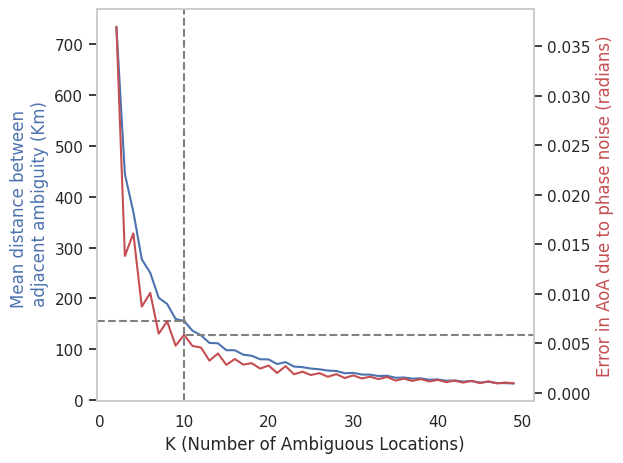

In [33]:
fig = plt.figure()
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

c = 3e8
lam = c/11.325e9
pi = np.pi
noise = 0.1 # rad
# distance coeff K (D=K*lam/2)
K = np.arange(2, 50)
print(K)
mean_dist_perambiguity = []
mean_noise_impact_perambiguity = []
for num_ambiguity in K:
    D = num_ambiguity*lam/2
    k = np.arange(int(-num_ambiguity/2), int(num_ambiguity/2)+1)
    print("k", k)
    aoa_elevations = np.arange(70, 91, 5) # in degrees
    aoa_elevations = np.radians(aoa_elevations)
    dist_diffs_peraoa = []
    error_with_noise_peraoa = []
    for e in aoa_elevations:
        del_phi = 2*pi*D*np.cos(e)/lam
        del_phi_ = 2*pi*D*np.cos(e)/lam + noise
        angles = np.arccos(del_phi*lam/(2*pi*D) + k*lam/D)
        angle_with_noise = np.arccos(del_phi_*lam/(2*pi*D) + k*lam/D)
        error_with_noise = np.abs(angles - angle_with_noise)
        error_with_noise = error_with_noise[~np.isnan(error_with_noise)]
        error_with_noise_peraoa.append(np.mean(error_with_noise))
        diff_angles = np.diff(angles)
        # remove if nan values exist
        diff_angles = diff_angles[~np.isnan(diff_angles)]
        dist_diffs = diff_angles*600
        mean_dist_diff = np.mean(dist_diffs)
        dist_diffs_peraoa.append(mean_dist_diff)
        print("dist_diffs", dist_diffs, "mean", mean_dist_diff)
    mean_dist_perambiguity.append(np.mean(dist_diffs_peraoa))
    mean_noise_impact_perambiguity.append(np.mean(error_with_noise_peraoa))
mean_dist_perambiguity = np.abs(mean_dist_perambiguity)
mean_noise_impact_perambiguity = np.array(mean_noise_impact_perambiguity)
# plt.figure()
ax1.plot(K, mean_dist_perambiguity)
ax1.set_xlabel('K (Number of Ambiguous Locations)', fontsize=12)
ax1.set_ylabel('Mean distance between \n adjacent ambiguity (Km)', color='b', fontsize=12)
ax2.set_ylabel('Error in AoA due to phase noise (radians)', color='r', fontsize=12)
ax2.plot(K, mean_noise_impact_perambiguity, 'r')
# draw 
# invert y axis for ax2
# ax2.invert_yaxis()
# turn off grid for ax2 and ax1
ax1.grid(False)
ax2.grid(False)
# draw verical line at K=10
ax1.axvline(x=10, color='grey', linestyle='dashed')
# draw horizontal line to ax2 where K=10
ax2.axhline(y=mean_noise_impact_perambiguity[8], xmin=10/49, color='grey', linestyle='dashed')
# draw horizontal line to ax1 where K=10
ax1.axhline(y=mean_dist_perambiguity[8], xmax=10/49, color='grey', linestyle='dashed')
# save with high DPI
# save figure with both axes
figure = plt.gcf()
figure.tight_layout()
plt.savefig('ambiguity_res_tradeoff.pdf')
plt.show()

### Plot coarse location error

Text(0, 0.5, 'Coarse Location Error (Km)')

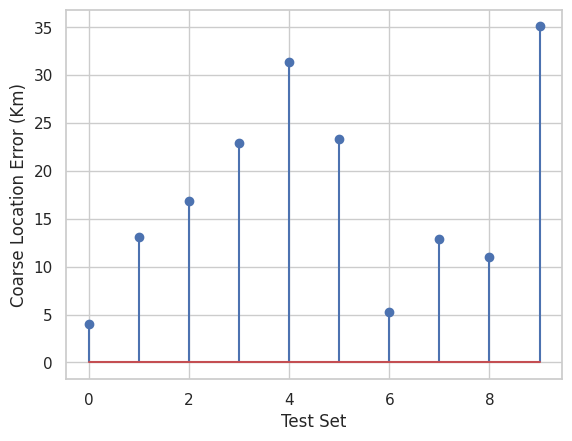

In [28]:
# plotting coarse gs error
coarse_gs_err = [res_dict[dir]['coarse_loc_err'] for dir in res_dirs]
coarse_gs_err = np.array(coarse_gs_err)
coarse_gs_err = np.sort(coarse_gs_err)
plt.stem(coarse_gs_err)
plt.xlabel('Test Set')
plt.ylabel('Coarse Location Error (Km)')

In [40]:
for dir in res_dirs:
    print(dir, res_dict[dir]['gt'], res_dict[dir]['loc_coords'], res_dict[dir]['phase_err_overall'])

13Mar2024_03_59 [ 40.11142412 -88.16207355] [40.10555569637516, -88.18155173082116] 1782.3264171827332
13Mar2024_03_17 [ 40.11183436 -88.20519719] [40.106868767459765, -88.2282169914408] 2036.2612652617888
12Mar2024_23_35 [ 40.10738645 -88.28293988] [40.11054637278699, -88.30831902997882] 2189.2483327429113
13Mar2024_02_20 [ 40.14188631 -88.22031649] [40.155880247926135, -88.19492445580234] 2663.790609185643
13Mar2024_00_54 [ 40.10243797 -88.33240108] [40.10740355922349, -88.3270895552549] 714.2045428920565
13Mar2024_00_35 [ 40.1024458  -88.33238779] [40.10741138727757, -88.33533863589481] 607.1882398791253
12Mar2024_23_17 [ 40.10738315 -88.28293573] [40.082555191795805, -88.29060849457768] 2839.9741006924196
13Mar2024_05_37 [ 40.10096119 -88.23833465] [40.10953812212754, -88.25072794460576] 1423.0957043724923
20Feb2024_23_19 [ 40.07214864 -88.20947974] [40.05544619954881, -88.22422741663277] 2243.9310112327744
6Mar2024_03_51 [ 40.11614837 -88.22277704] [40.14278198783926, -88.19621404

In [30]:
# print mean of overall
phase_err_overall = np.array([res_dict[dir]['phase_err_overall'] for dir in res_dict], dtype=np.float64)
dopp_baseline_overall = np.array([res_dict[dir]['dopp_baseline_overall'] for dir in res_dict], dtype=np.float64)
print('phase_err_overall', np.mean(phase_err_overall), np.std(phase_err_overall))
print('dopp_baseline_overall', np.mean(dopp_baseline_overall), np.std(dopp_baseline_overall))


phase_err_overall 2017.670364157456 863.5329037800615
dopp_baseline_overall 3454.91785504217 1133.967885161968
